# 07 · Targeting policy and business impact

**Goal:** turn the findings into a decision: for each customer, send the Mens email, the Womens email, or nothing. Then estimate what each policy would deliver, compared with (a) emailing everyone and (b) emailing no one, on held-out customers, with uncertainty and stated assumptions.

**Objective:** incremental spend per customer over the two-week window, **net of the cost of sending the email**.

### Assumptions (read these before the numbers)

1. **Two-week horizon.** Effects after two weeks (purchases pulled forward or delayed, unsubscribes, email fatigue) are not in the data and are ignored.
2. **Revenue, not profit.** `spend` is revenue. With a gross margin $m$, every dollar figure below should be multiplied by $m$ before comparing it with costs; the break-even costs shown here are therefore upper bounds.
3. **Email cost is unknown.** Instead of assuming one number, results are shown across a range of costs per email, from \$0 to \$1.
4. **Visit uplift is used as the targeting signal.** Notebook 06 showed that no spend model beats random targeting, while visit models do. Visit uplift is converted to dollars with one number per email: the average extra spend per extra visit, estimated on the training set. This assumes an extra visit is worth the same, on average, for every customer who receives a given email, a simplification.
5. **The data is from 2008.** Customer behaviour and email performance today may differ.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hillstrom.data import load_customers
from hillstrom.plots import ARM_COLORS, ARM_LABELS, TEXT_PRIMARY, TEXT_SECONDARY, apply_style, save_figure
from hillstrom.policy import assign_policy, bootstrap_policy_value, policy_value_ipw
from hillstrom.uplift import TLearner, make_features, split_train_test

apply_style()
df = load_customers()
train, test = split_train_test(df)  # same split and seed as notebook 06
EMAILS = ["mens", "womens"]
arm_test = test["arm"].to_numpy()
n_test = len(test)
print(f"Policies are learned on {len(train):,} training customers and evaluated on {n_test:,} test customers.")

Policies are learned on 44,800 training customers and evaluated on 19,200 test customers.


## 1. From visit uplift to dollars

For each email, the training set gives the average effect on visits and on spend. Their ratio is the average extra spend per extra visit.

In [2]:
dollars_per_visit = {}
rows = []
for email in EMAILS:
    tr = train[train["arm"].isin([email, "control"])]
    is_email = tr["arm"] == email
    visit_effect = tr.loc[is_email, "visit"].mean() - tr.loc[~is_email, "visit"].mean()
    spend_effect = tr.loc[is_email, "spend"].mean() - tr.loc[~is_email, "spend"].mean()
    dollars_per_visit[email] = spend_effect / visit_effect
    rows.append({"email": ARM_LABELS[email], "visit_effect_pp": 100 * visit_effect,
                 "spend_effect": spend_effect, "dollars_per_extra_visit": dollars_per_visit[email]})
pd.DataFrame(rows).style.format(
    {"visit_effect_pp": "{:+.2f}", "spend_effect": "${:+.3f}", "dollars_per_extra_visit": "${:.2f}"}
).hide(axis="index")

email,visit_effect_pp,spend_effect,dollars_per_extra_visit
Mens E-Mail,+7.78,$+0.771,$9.92
Womens E-Mail,+4.68,$+0.472,$10.08


Both emails turn an extra visit into about \$10 of extra spend on average. Each customer's estimated dollar uplift is their predicted visit uplift times this number.

The two targeting signals from notebook 06 are refit here on the training set:

- **Segment rule:** each customer gets their `purchase_group`'s visit effect (three numbers per email).
- **Linear T-learner:** each customer gets their individual predicted visit uplift.

In [3]:
X_test = make_features(test)
dollar_uplift = {}
for email in EMAILS:
    tr = train[train["arm"].isin([email, "control"])]
    treated = (tr["arm"] == email).to_numpy()

    model = TLearner("binary", base="linear").fit(make_features(tr), tr["visit"].to_numpy(), treated)
    dollar_uplift["Linear T-learner", email] = model.predict_uplift(X_test) * dollars_per_visit[email]

    group_effect = {
        group: g.loc[g["arm"] == email, "visit"].mean() - g.loc[g["arm"] == "control", "visit"].mean()
        for group, g in tr.groupby("purchase_group")
    }
    dollar_uplift["Segment rule", email] = test["purchase_group"].map(group_effect).to_numpy() * dollars_per_visit[email]

TARGETED = ["Segment rule", "Linear T-learner"]
FIXED = {"No email": "control", "Mens E-Mail to all": "mens", "Womens E-Mail to all": "womens"}


def policy(name: str, cost: float) -> np.ndarray:
    # The action for every test customer under a named policy at a given cost per email.
    if name in FIXED:
        return np.full(n_test, FIXED[name])
    return assign_policy(dollar_uplift[name, "mens"], dollar_uplift[name, "womens"], cost)

**Decision rule for the targeted policies:** for each customer, pick the action with the largest estimated net gain: Mens email (dollar uplift − cost), Womens email (dollar uplift − cost), or nothing (0). A customer is emailed only if the best net gain is positive.

## 2. How a policy is evaluated: inverse propensity weighting (IPW)

A policy was never actually run, so its value has to be estimated from the experiment. In the experiment every customer had a 1/3 chance of receiving each action. The customers whose *actual* arm happens to match what the policy would choose are therefore a random third of the customers the policy would treat that way. Their outcomes, weighted by 1/(1/3) = 3, estimate what the policy would deliver:

$$\hat V(\pi) = \frac{1}{n}\sum_{i=1}^{n} \frac{\mathbb{1}[A_i = \pi(x_i)]\; Y_i}{1/3} \;-\; \text{cost} \times \text{share emailed}.$$

This uses only observed outcomes, not the model's own predictions, so a wrong model cannot make its own policy look good. The price is noise: each policy's value rests on about a third of the test customers. Intervals come from 1,000 bootstrap resamples of the test customers, using the same resamples for every policy so that policies can be compared pairwise.

## 3. Policy value across email costs

For each cost per email from \$0 to \$1, the chart shows each policy's net spend per customer **minus** the no-email policy's spend, so "No email" is the zero line. Point estimates only; intervals follow in the table below.

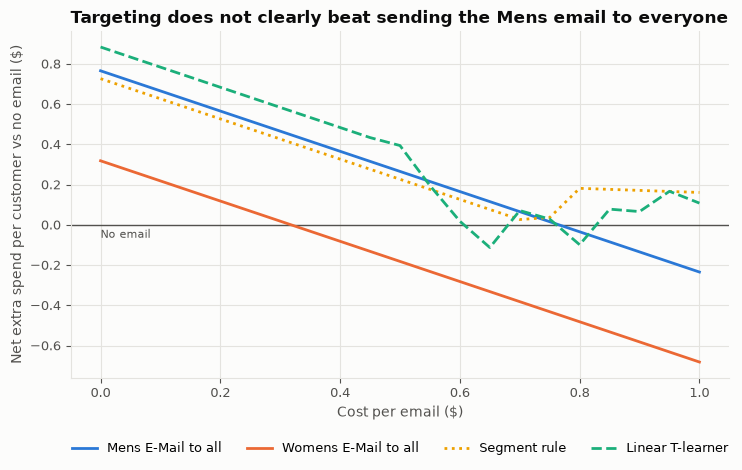

In [4]:
y_spend = test["spend"].to_numpy()
costs = np.round(np.arange(0, 1.0001, 0.05), 2)
POLICIES = ["Mens E-Mail to all", "Womens E-Mail to all", *TARGETED]

value_none = policy_value_ipw(policy("No email", 0), arm_test, y_spend)
grid = pd.DataFrame(
    [
        {"cost": c, "policy": name,
         "net_vs_none": policy_value_ipw(policy(name, c), arm_test, y_spend, cost=c) - value_none,
         "share_emailed": np.mean(policy(name, c) != "control")}
        for c in costs
        for name in POLICIES
    ]
)

STYLES = {
    "Mens E-Mail to all": dict(color=ARM_COLORS["mens"], ls="-"),
    "Womens E-Mail to all": dict(color=ARM_COLORS["womens"], ls="-"),
    "Segment rule": dict(color="#eda100", ls=":"),
    "Linear T-learner": dict(color="#1baf7a", ls="--"),
}
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.axhline(0, color=TEXT_SECONDARY, lw=1)
ax.text(0.0, -0.02, "No email", ha="left", va="top", fontsize=8, color=TEXT_SECONDARY)
for name in POLICIES:
    sub = grid[grid["policy"] == name]
    ax.plot(sub["cost"], sub["net_vs_none"], lw=2, label=name, **STYLES[name])
ax.set_xlabel("Cost per email ($)")
ax.set_ylabel("Net extra spend per customer vs no email ($)")
ax.set_title("Targeting does not clearly beat sending the Mens email to everyone", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
save_figure(fig, "07_policy_value_by_cost")
plt.show()

### With uncertainty, at five illustrative costs

For each targeted policy: the share of customers it emails and its net spend per customer compared with three alternatives:

- **vs Mens to all:** the best single-email policy;
- **vs No email;**
- **vs random targeting with the same mix:** emailing the same shares of customers with Mens and Womens, but chosen at random. This isolates the value of *choosing who*, separately from *how many*. Its value is computed exactly from the fixed policies: $\sum_a \text{share}_a \times \hat V(\text{all } a)$.

Brackets are 95% paired-bootstrap intervals.

In [5]:
def gross_value(action: str) -> float:
    return policy_value_ipw(np.full(n_test, action), arm_test, y_spend)


def interval(point: float, d: np.ndarray) -> str:
    # Point estimate with its 95% bootstrap interval.
    low, high = np.percentile(d, [2.5, 97.5])
    return f"{point:+.2f} [{low:+.2f}, {high:+.2f}]"


table_rows = []
for c in [0.0, 0.25, 0.5, 0.75, 1.0]:
    draws_mens = bootstrap_policy_value(policy("Mens E-Mail to all", c), arm_test, y_spend, cost=c)
    draws_none = bootstrap_policy_value(policy("No email", c), arm_test, y_spend)
    value_mens = policy_value_ipw(policy("Mens E-Mail to all", c), arm_test, y_spend, cost=c)
    for name in TARGETED:
        pol = policy(name, c)
        share = {a: np.mean(pol == a) for a in ["control", "mens", "womens"]}
        value = policy_value_ipw(pol, arm_test, y_spend, cost=c)
        random_same_mix = sum(share[a] * gross_value(a) for a in share) - c * (1 - share["control"])
        d = bootstrap_policy_value(pol, arm_test, y_spend, cost=c)
        table_rows.append(
            {
                "cost": f"${c:.2f}",
                "policy": name,
                "emailed": f"{1 - share['control']:.0%} (M {share['mens']:.0%} / W {share['womens']:.0%})",
                "vs Mens to all ($)": interval(value - value_mens, d - draws_mens),
                "vs No email ($)": interval(value - value_none, d - draws_none),
                "vs random, same mix ($)": f"{value - random_same_mix:+.2f}",
            }
        )
pd.DataFrame(table_rows).style.hide(axis="index")

cost,policy,emailed,vs Mens to all ($),vs No email ($),"vs random, same mix ($)"
$0.00,Segment rule,100% (M 55% / W 45%),"-0.04 [-0.37, +0.30]","+0.73 [+0.21, +1.28]",+0.16
$0.00,Linear T-learner,100% (M 68% / W 32%),"+0.12 [-0.13, +0.39]","+0.88 [+0.34, +1.43]",+0.26
$0.25,Segment rule,100% (M 55% / W 45%),"-0.04 [-0.37, +0.30]","+0.48 [-0.04, +1.03]",+0.16
$0.25,Linear T-learner,100% (M 68% / W 32%),"+0.12 [-0.13, +0.39]","+0.63 [+0.09, +1.18]",+0.26
$0.50,Segment rule,100% (M 55% / W 45%),"-0.04 [-0.37, +0.30]","+0.23 [-0.29, +0.78]",+0.16
$0.50,Linear T-learner,100% (M 68% / W 32%),"+0.13 [-0.12, +0.39]","+0.39 [-0.15, +0.94]",+0.27
$0.75,Segment rule,55% (M 10% / W 45%),"+0.02 [-0.50, +0.55]","+0.04 [-0.30, +0.43]",+0.23
$0.75,Linear T-learner,54% (M 34% / W 21%),"+0.01 [-0.43, +0.44]","+0.03 [-0.37, +0.43]",+0.11
$1.00,Segment rule,10% (M 10% / W 0%),"+0.40 [-0.11, +0.90]","+0.16 [-0.04, +0.39]",+0.18
$1.00,Linear T-learner,10% (M 10% / W 0%),"+0.34 [-0.18, +0.85]","+0.11 [-0.07, +0.29]",+0.13


## 4. Gross impact per 1,000 customers

At zero email cost, the extra visits, conversions and revenue each policy would bring per 1,000 customers compared with sending nothing, over two weeks (IPW estimates on the test set, 95% bootstrap intervals).

In [6]:
impact_rows = []
for name in POLICIES:
    pol = policy(name, 0.0)
    row = {"policy": name}
    for metric, label in [("visit", "extra visits"), ("conversion", "extra conversions"), ("spend", "extra revenue ($)")]:
        y = test[metric].to_numpy()
        point = 1000 * (policy_value_ipw(pol, arm_test, y) - policy_value_ipw(policy("No email", 0), arm_test, y))
        d = 1000 * (bootstrap_policy_value(pol, arm_test, y) - bootstrap_policy_value(policy("No email", 0), arm_test, y))
        low, high = np.percentile(d, [2.5, 97.5])
        row[label] = f"{point:+.0f} [{low:+.0f}, {high:+.0f}]"
    impact_rows.append(row)
pd.DataFrame(impact_rows).style.hide(axis="index")

policy,extra visits,extra conversions,extra revenue ($)
Mens E-Mail to all,"+74 [+61, +86]","+8 [+4, +11]","+765 [+232, +1302]"
Womens E-Mail to all,"+42 [+30, +54]","+2 [-1, +5]","+318 [-198, +824]"
Segment rule,"+76 [+62, +88]","+6 [+3, +10]","+726 [+214, +1283]"
Linear T-learner,"+73 [+60, +85]","+8 [+5, +12]","+883 [+336, +1435]"


The IPW intervals here are wider than the direct arm comparisons in notebook 03 (for example, Mens vs no email on spend: about \$0.49 to \$1.05 per customer there). That is the cost of evaluating policies that were never run: each policy's value uses only the third of test customers whose arm matches it, and only the 30% test split.

## Recommendation

**1. Default: send the Mens email to everyone, as long as the cost per email is well below its effect.** It raised spend by about \$0.77 per customer over two weeks (notebook 03, interval \$0.49 to \$1.05, revenue). With a gross margin $m$, it pays off when the cost per email is below about $m \times \$0.77$; to be confident, below $m \times \$0.49$.

**2. Don't send the Womens email to customers who have only bought men's items.** This is the clearest targeting finding in the data (notebook 06): the Womens email adds about 1 extra visit per 100 such customers, against about 7 per 100 for everyone else. In every group, the Mens email performs about as well as the Womens email or better, so the data never shows the Womens email to be the clearly better choice.

**3. Targeting is only worth considering when emails are expensive.** Near and above the Mens email's break-even cost, both targeted policies switch to emailing only the customers with the largest estimated effect, chiefly those who bought both categories. At \$1 per email, the two targeted policies are the only ones with positive point estimates (about +\$0.11 to +\$0.16 per customer vs no email), but their intervals include zero. It is a hypothesis, not a result.

**4. Validate before rolling out.** The honest next step is a new experiment that randomizes customers between "Mens email to all" and "targeted policy". That would measure the targeting gain directly, instead of re-weighting a few hundred buyers from an experiment designed for a different question.

## What we cannot claim

- **That targeting beats emailing everyone.** At every cost tested, the difference between the targeted policies and "Mens to all" has an interval that includes zero.
- **That the linear T-learner is better than the segment rule or than "Mens to all".** Its point estimate at low cost is higher (about +\$0.12 per customer vs "Mens to all"), but the interval runs from about −\$0.13 to +\$0.39.
- **Profit.** All dollar figures are revenue over two weeks; margin and long-term effects are not in the data.
- **Today's numbers.** The experiment ran in 2008.